In [1]:
import wn
import hcc
import os
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.decomposition import PCA
import umap
import csv

/root/anaconda3/envs/zxr_hcc1/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-07-04 06:43:31.112925: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-04 06:43:31.183526: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-07-04 06:43:31.216318: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-07-04 06:43:31.2

In [2]:
def to_synset(input):
    """Returns the synset 'xxx' for input string 'Synset(xxx)'"""
    idx = input[8:-2]
    synset = wn.synset(idx)
    return synset

def to_synset_scp(input, wordnet=None):
    synsets = wordnet.synsets(input[1:-1])
    if len(synsets) == 0:
        raise ValueError(f"No synset found for {input} in {wordnet}")
    else:
        return synsets[0]
    
def to_synset_scp_img(input, wordnet=None):
    return wordnet.synset(input[1:-1])

def to_depth(input):
    ss = to_synset(input)
    depth = hcc.utils.max_synset_depth(ss)
    return depth

def to_human_readable(input):
    if 'subset-' in input:
        input = input.replace('subset-', '')
    ss = to_synset(input)
    return ss.lemmas()[0]

In [3]:
OOD_detection = False
datasets = [
    #("LCA_TS_celltypist_0.05", "output/LCA_TS/hcc_result/popv_celltypist_prediction_0.05_0.25_output.csv", 0.25),
    # ("LCA_TS_celltypist_0.05_leaf", "output/LCA_TS/hcc_result/popv_celltypist_prediction_0.05_0.25_leaf_output.csv", 0.25),
    #("LCA_TS_celltypist_0.01", "output/LCA_TS/hcc_result/popv_celltypist_prediction_0.01_0.25_output.csv", 0.25),
    # ("LCA_TS_celltypist_0.01_leaf", "output/LCA_TS/hcc_result/popv_celltypist_prediction_0.01_0.25_leaf_output.csv", 0.25),
    #("LCA_TS_celltypist_0.005", "output/LCA_TS/hcc_result/popv_celltypist_prediction_0.005_0.25_output.csv", 0.25),
    # ("LCA_TS_celltypist_0.005_leaf", "output/LCA_TS/hcc_result/popv_celltypist_prediction_0.005_0.25_leaf_output.csv", 0.25),

    # ("celltypist_0.05", "output/LCA/hcc_result/popv_celltypist_prediction_0.05_0.25_output.csv", 0.25),
    # ("celltypist_0.05_leaf", "output/LCA/hcc_result/popv_celltypist_prediction_0.05_0.25_leaf_output.csv", 0.25),
    ("celltypist_0.01", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.25_output.csv", 0.25),
    # ("celltypist_0.01_leaf", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.25_leaf_output.csv", 0.25),
    # ("celltypist_0.005", "output/LCA/hcc_result/popv_celltypist_prediction_0.005_0.25_output.csv", 0.25),
    # ("celltypist_0.005_leaf", "output/LCA/hcc_result/popv_celltypist_prediction_0.005_0.25_leaf_output.csv", 0.25),

    #("celltypist_0.01", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.25_output.csv", 0.25),
    # ("bbknn_0.01", "output/LCA/hcc_result/popv_knn_bbknn_prediction_0.01_0.25_output.csv", 0.25),
    #("scvi_0.01", "output/LCA/hcc_result/popv_knn_on_scvi_prediction_0.01_0.25_output.csv", 0.25),
    #("rf_0.01", "output/LCA/hcc_result/popv_rf_prediction_0.01_0.25_output.csv", 0.25),
    #("scanvi_0.01", "output/LCA/hcc_result/popv_scanvi_prediction_0.01_0.25_output.csv", 0.25),
    #("xgboost_0.01", "output/LCA/hcc_result/popv_xgboost_prediction_0.01_0.25_output.csv", 0.25),
    #("svm_0.01", "output/LCA/hcc_result/popv_svm_prediction_0.01_0.25_output.csv", 0.25),

    # ("celltypist_0.01_0", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0_output.csv", 0),
    # ("celltypist_0.01_0.1", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.1_output.csv", 0.1),
    # ("celltypist_0.01_0.2", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.2_output.csv", 0.2),
    # ("celltypist_0.01_0.3", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.3_output.csv", 0.3),
    # ("celltypist_0.01_0.4", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.4_output.csv", 0.4),
    # ("celltypist_0.01_0.5", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.5_output.csv", 0.5),
    # ("celltypist_0.01_0.6", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.6_output.csv", 0.6),
    # ("celltypist_0.01_0.7", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.7_output.csv", 0.7),
    # ("celltypist_0.01_0.8", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.8_output.csv", 0.8),
    # ("celltypist_0.01_0.9", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.9_output.csv", 0.9),
    # ("celltypist_0.01_1", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_1_output.csv", 1),

    #("celltypist_0.05_nobc", "output/LCA/hcc_result/popv_celltypist_prediction_0.05_0.25_nobc_output.csv", 0.25),
    #("celltypist_0.05_ml", "output/LCA/hcc_result/popv_celltypist_prediction_0.05_0.25_ml_output.csv", 0.25),
    #("celltypist_0.01_nobc", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.25_nobc_output.csv", 0.25),
    #("celltypist_0.01_ml", "output/LCA/hcc_result/popv_celltypist_prediction_0.01_0.25_ml_output.csv", 0.25),
    #("celltypist_0.005_nobc", "output/LCA/hcc_result/popv_celltypist_prediction_0.005_0.25_nobc_output.csv", 0.25),
    #("celltypist_0.005_ml", "output/LCA/hcc_result/popv_celltypist_prediction_0.005_0.25_ml_output.csv", 0.25),

    # ("TS_celltypist_0.05", "output/TS/hcc_result/popv_celltypist_prediction_0.05_0.25_output.csv", 0.25),
    # ("TS_celltypist_0.05_leaf", "output/TS/hcc_result/popv_celltypist_prediction_0.05_0.25_leaf_output.csv", 0.25),
    # ("TS_celltypist_0.01", "output/TS/hcc_result/popv_celltypist_prediction_0.01_0.25_output.csv", 0.25),
    # ("TS_celltypist_0.01_leaf", "output/TS/hcc_result/popv_celltypist_prediction_0.01_0.25_leaf_output.csv", 0.25),
    # ("TS_celltypist_0.005", "output/TS/hcc_result/popv_celltypist_prediction_0.005_0.25_output.csv", 0.25),
    # ("TS_celltypist_0.005_leaf", "output/TS/hcc_result/popv_celltypist_prediction_0.005_0.25_leaf_output.csv", 0.25),

    # ("CICA_celltypist_0.05", "output/CICA/hcc_result/popv_celltypist_prediction_0.05_0.25_output.csv", 0.25),
    # ("CICA_celltypist_0.05_leaf", "output/CICA/hcc_result/popv_celltypist_prediction_0.05_0.25_leaf_output.csv", 0.25),
    # ("CICA_celltypist_0.01", "output/CICA/hcc_result/popv_celltypist_prediction_0.01_0.25_output.csv", 0.25),
    # ("CICA_celltypist_0.01_leaf", "output/CICA/hcc_result/popv_celltypist_prediction_0.01_0.25_leaf_output.csv", 0.25),
    # ("CICA_celltypist_0.005", "output/CICA/hcc_result/popv_celltypist_prediction_0.005_0.25_output.csv", 0.25),
    # ("CICA_celltypist_0.005_leaf", "output/CICA/hcc_result/popv_celltypist_prediction_0.005_0.25_leaf_output.csv", 0.25),

]

In [13]:
if OOD_detection:
    df_read = pd.read_csv('LCA_TS_OOD_0.3.txt', sep='\t', index_col=0)
    df_read['OOD'] = df_read['OOD'].astype(bool)
    ood_filtered_idx = df_read[~df_read['OOD']].index
    adata = sc.read_h5ad('output/LCA_TS/probability_matrix/processed.h5ad')
    query_adata = adata[adata.obs['split'].isin(['test','calibrate'])]
    row_indices = np.where(query_adata.obs_names.isin(ood_filtered_idx))[0]

In [4]:
for _, f, _ in datasets:
    if not os.path.isfile(f):
        print(f"File {f} does not exist.")

Compare the HCC method with Standard CP and LCA methods using four metrics: Coverage, Prediction set size, Number of covered leaves, and Cost.

In [5]:
results = {}
wordnet = wn.Wordnet("LCA_TS-en")
for name, dataset, beta in datasets:
    print(f"Dataset: {name}")
    get_lca = False
    if "_leaf" in name:
        get_lca = True
        
    leaves = hcc.utils.all_leaves(wordnet)
    df = pd.read_csv(dataset)

    if OOD_detection:
        df = df[df['Unnamed: 0'].isin(row_indices)]
    
    df['covered'] = False
    df['prediction_set_ss'] = None
    depths = pd.Series(dtype=object)
    best_cover_lens = []
    df['prediction_set_ss'] = df['prediction_set'].map(
            lambda x: frozenset(map(to_synset, x[1:-1].split(", ")))
        )
    df['label_ss'] = df['label'].map(to_synset)
    df['covered'] = df.apply(
            lambda x: hcc.no_cover.covers_all_nodes(x['prediction_set_ss'], frozenset({x['label_ss']})),
            axis=1
        )
    df['n_covered'] = df.apply(
            lambda x: len(hcc.no_cover.covered_nodes(x['prediction_set_ss'], leaves)),
            axis=1
        )
    df['costs'] = df['prediction_set_ss'].map(
            lambda x:
                hcc.costs.cost(
                    beta,
                    x,
                    leaves,
                    None,
                    cost_function_empty = 0.0
            )[0]
        )
    df['WSR'] = df.apply(
        lambda x: x['covered'] * (x['prediction_set_len']==1) / max(x['n_covered'],1),
        axis = 1
    )
    if get_lca:
        df['lca'] = df['prediction_set_ss'].map(hcc.utils.get_lca)
        df['lca_covered'] = df.apply(lambda x: hcc.no_cover.covers_all_nodes(frozenset({x['lca']}), frozenset({x['label_ss']})), axis=1)
        df['lca_n_covered'] = df['lca'].map(lambda x: len(hcc.no_cover.covered_nodes(frozenset({x}), leaves)))
        df['lca_costs'] = df.apply(lambda x: 1 + beta * x['lca_n_covered'], axis=1)
        df['lca_WSR'] = df.apply(
            lambda x: x['lca_covered'] / max(x['lca_n_covered'],1),
            axis = 1
        )
    results[name] = {
            'covered': df.covered.mean(),
            'covered_std': df.covered.std(),
            'covered_sem': df.covered.sem(),
            'alpha': df.alpha.mean(),
            'bf_alpha': df.bf_alpha.mean(),
            'beta': df.beta.mean(),
            'ps_len_mean': df.prediction_set_len.mean(),
            'ps_lens': df.prediction_set_len,
            # 'label_depth': df.label_depth,
            # 'label_dists': depths - df.label_depth,
            # 'depths': depths,
            'n_covered': df.n_covered,
            'best_cover_lens': df['best_cover'].apply(len),
            'costs': df['costs'],
            'df': df,
            'WSR': df['WSR'].mean(),
            }
    if get_lca:
        results[name].update({
            'lca_covered': df.lca_covered.mean(),
            'lca_covered_std': df.lca_covered.std(),
            'lca_covered_sem': df.lca_covered.sem(),
            'lca_n_covered': df.lca_n_covered,
            'lca_costs': df['lca_costs'],
            'lca_WSR': df['lca_WSR'].mean(),
        })

Dataset: celltypist_0.01


In [6]:
for name, _ , _ in datasets:
    result = results[name]
    print(f"Name: {name}, Coverage: {result['covered']:.4f} pm {result['covered_std']:.4f}, PS size: {result['ps_len_mean']:.2f} pm {result['ps_lens'].std():.2f}, # covered: {result['n_covered'].mean():.2f} pm {result['n_covered'].std():.2f}, Cost: {result['costs'].mean():.2f} pm {result['costs'].std():.2f}, WSR: {result['WSR']:.4f}")
    if "_leaf" in name:
        print(f"Name: {name}_lca, Coverage: {result['lca_covered']:.4f} pm {result['lca_covered_std']:.4f}, PS size: {1:.2f} pm 0.00, # covered: {result['lca_n_covered'].mean():.2f} pm {result['lca_n_covered'].std():.2f}, Cost: {result['lca_costs'].mean():.2f} pm {result['lca_costs'].std():.2f}, WSR: {result['lca_WSR']:.4f}")

output_file = "results.csv"

with open(output_file, "w", newline="") as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow([
        "Name", 
        "Coverage", "Coverage_std", 
        "PS_size", "PS_size_std", 
        "#covered", "#covered_std", 
        "Cost", "Cost_std",
        "WSR",
    ])
    
    for name, _, _ in datasets:
        result = results[name]

        row_normal = [
            name,
            f"{result['covered']:.4f}", f"{result['covered_std']:.4f}",
            f"{result['ps_len_mean']:.2f}", f"{result['ps_lens'].std():.2f}",
            f"{result['n_covered'].mean():.2f}", f"{result['n_covered'].std():.2f}",
            f"{result['costs'].mean():.2f}", f"{result['costs'].std():.2f}",
            f"{result['WSR'].mean():.4f}"
        ]
        writer.writerow(row_normal)

        if "_leaf" in name:
            row_lca = [
                f"{name}_lca",
                f"{result['lca_covered']:.4f}", f"{result['lca_covered_std']:.4f}",
                "1.00", "0.00",
                f"{result['lca_n_covered'].mean():.2f}", f"{result['lca_n_covered'].std():.2f}",
                f"{result['lca_costs'].mean():.2f}", f"{result['lca_costs'].std():.2f}",
                f"{result['lca_WSR'].mean():.4f}"
            ]
            writer.writerow(row_lca)

Name: celltypist_0.01, Coverage: 0.9935 pm 0.0806, PS size: 1.18 pm 0.39, # covered: 3.49 pm 3.03, Cost: 2.05 pm 0.78, WSR: 0.4724


Visualize the positions of ambiguous cells (Number of covered leaves >= 4) in the HCC prediction results.

In [7]:
adata = sc.read_h5ad('output/LCA/probability_matrix/processed.h5ad')
ref_adata = adata[adata.obs['split'] == 'train']
query_adata = adata[adata.obs['split'] == 'test']
adata

AnnData object with n_obs × n_vars = 56423 × 1000
    obs: 'nGene', 'nUMI', 'channel', 'region', 'percent.ribo', 'free_annotation', 'donor_id', 'sample', 'location', 'magnetic.selection', 'preparation.site', 'compartment', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'development_stage_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'split', '_batch_annotation', 'n_counts', '_dataset', '_reference_labels_annotation', '_labels_annotation', '_ref_subsample', '_labelled_train_indices', '_predict_cells'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'mean', 'std'
    uns: 'Filtered_cells', '_cl_obo_file', '_cl_ontology_file', '_nlp_emb_file', 

In [8]:
query_adata.obs['unclear'] = results['celltypist_0.01']['n_covered'].values>=4
for i in range(len(query_adata.obs['unclear'])):
    if query_adata.obs['unclear'].iloc[i]:
        query_adata.obs['unclear'].iloc[i] = 'High‑uncertainty cells'
    else:
        query_adata.obs['unclear'].iloc[i] = 'Low‑uncertainty cells'

/tmp/ipykernel_12081/216244001.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  query_adata.obs['unclear'] = results['celltypist_0.01']['n_covered'].values>=4
/tmp/ipykernel_12081/216244001.py:4: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stabl

In [9]:
random.seed(42)
np.random.seed(42)

pca_calib = query_adata.obsm['X_pca'][:, :40]
umap_model = umap.UMAP(n_neighbors=15, min_dist=1, random_state=42)
umap_model.fit(pca_calib)

query_adata.obsm['UMAP'] = umap_model.transform(pca_calib)
ref_adata.obsm['UMAP'] = umap_model.transform(ref_adata.obsm['X_pca'][:, :40])

/root/anaconda3/envs/zxr_hcc1/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_12081/4177089389.py:9: ImplicitModificationWarning: Setting element `.obsm['UMAP']` of view, initializing view as actual.
  ref_adata.obsm['UMAP'] = umap_model.transform(ref_adata.obsm['X_pca'][:, :40])


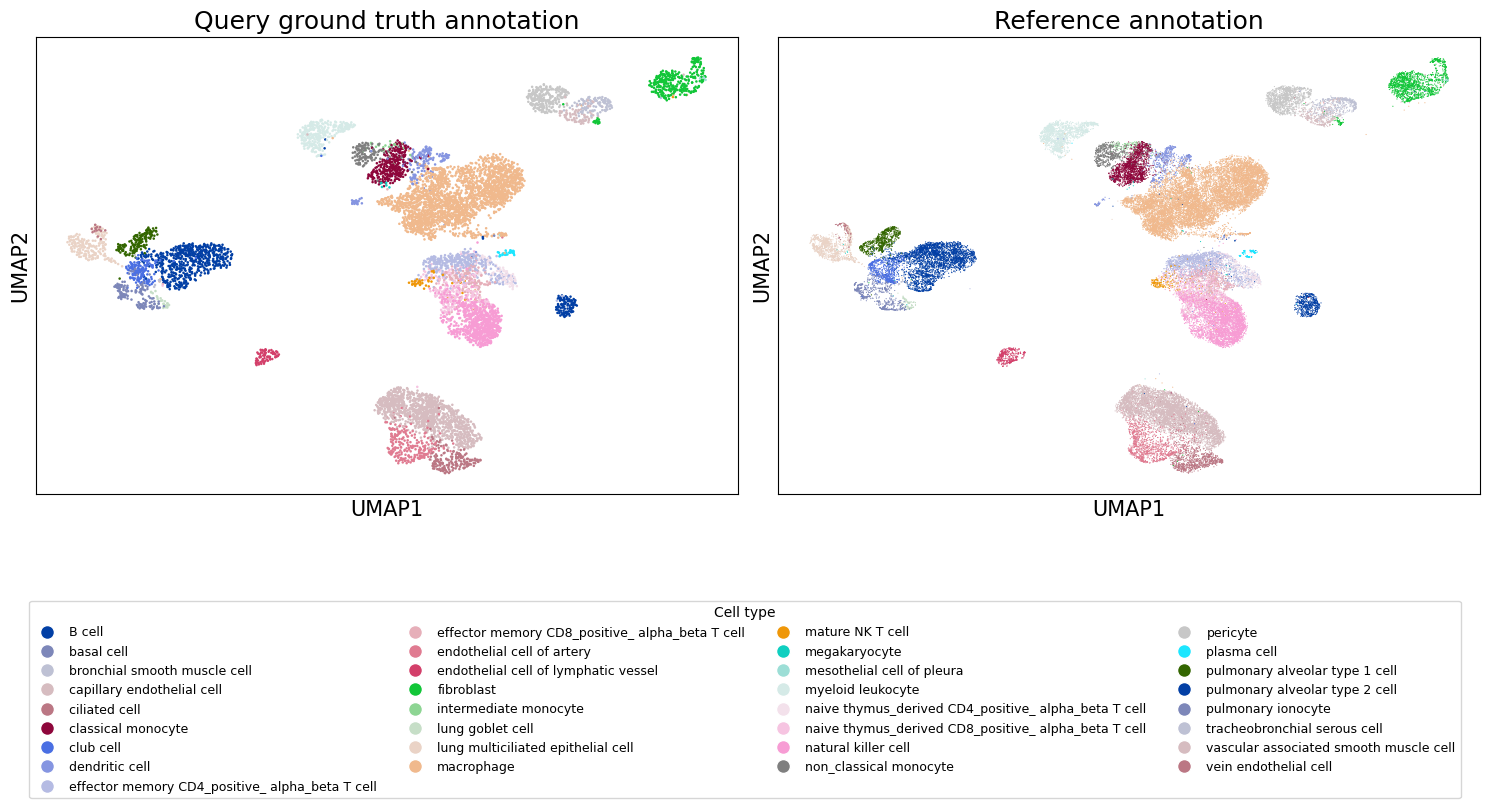

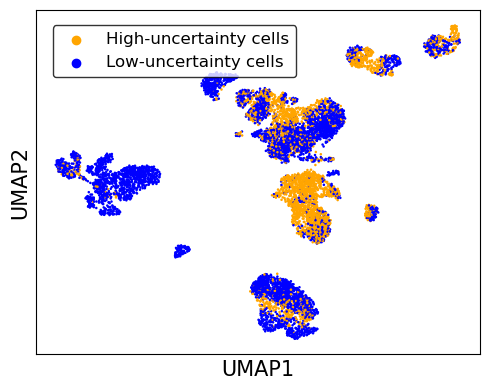

In [12]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
all_types = sorted(set(query_adata.obs['cell_type'].unique()) | set(ref_adata.obs['cell_type'].unique()))
palette = sc.pl.palettes.default_28
color_dict = {ct: palette[i % len(palette)] for i, ct in enumerate(all_types)}


fig, axes = plt.subplots(1, 2, figsize=(15, 6))


sc.pl.embedding(query_adata, basis='UMAP', color='cell_type', ax=axes[0],
                show=False, legend_loc='none', palette=color_dict, title='Query Annotation')
axes[0].set_xlabel(axes[0].get_xlabel(), fontsize=15)
axes[0].set_ylabel(axes[0].get_ylabel(), fontsize=15)


sc.pl.embedding(ref_adata, basis='UMAP', color='cell_type', ax=axes[1],
                show=False, legend_loc='none', palette=color_dict, title='Reference Annotation')
axes[1].set_xlabel(axes[1].get_xlabel(), fontsize=15)
axes[1].set_ylabel(axes[1].get_ylabel(), fontsize=15)

axes[0].set_title('Query ground truth annotation', fontsize=18)
axes[1].set_title('Reference annotation', fontsize=18)


handles = [Line2D([0], [0], marker='o', color='w', 
                  markerfacecolor=color_dict[ct], 
                  markersize=10, label=ct) for ct in all_types]

fig.legend(handles=handles, 
           bbox_to_anchor=(0.5, -0.1), 
           loc='upper center',
           ncol=4, 
           title='Cell type',
           fontsize=9)


plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig('figure/celltype_umap_combined.pdf', bbox_inches='tight')
plt.show()

categories = sorted(query_adata.obs['unclear'].unique())
color_dict_unclear = {'High‑uncertainty cells': 'orange', 'Low‑uncertainty cells': 'blue'}
palette_unclear = [color_dict_unclear[cat] for cat in categories]

fig2, ax = plt.subplots(figsize=(5, 4))
sc.pl.embedding(query_adata, basis='UMAP', color='unclear', title='',
                palette=palette_unclear, ax=ax, show=False)

handles2, labels2 = ax.get_legend_handles_labels()
if handles2:
    legend = ax.legend(handles2, labels2, 
                       loc='upper left',          
                       bbox_to_anchor=(0.02, 0.98),  
                       ncol=1,
                       frameon=True,              
                       facecolor='white',        
                       edgecolor='black',
                       fontsize = 12)       

ax.set_xlabel(ax.get_xlabel(), fontsize=15)
ax.set_ylabel(ax.get_ylabel(), fontsize=15)
ax.set_title(ax.get_title(), fontsize=15)
#ax.set_title('Cell Uncertainty Level', fontsize=18)
plt.tight_layout()
plt.savefig('figure/uncertainty_umap.pdf')
plt.show()

In [13]:
cell_type_key = 'cell_type'   
celltype1, celltype2 = 'effector memory CD4_positive_ alpha_beta T cell', 'effector memory CD8_positive_ alpha_beta T cell'
# Perform differential analysis on two target cell types.
sc.tl.rank_genes_groups(
    adata,
    groupby=cell_type_key,
    groups=[celltype1, celltype2],   
    reference='rest',       
    method='t-test_overestim_var',   
    key_added='rank_genes'
)
result = adata.uns['rank_genes']
groups = result['names'].dtype.names  

def get_marker_genes(adata, cell_type, logfc_threshold=1, pval_threshold=0.05):
    result = adata.uns['rank_genes']
    names = result['names'][cell_type]
    logfoldchanges = result['logfoldchanges'][cell_type]
    pvals_adj = result['pvals_adj'][cell_type]
    

    df = pd.DataFrame({
        'gene': names,
        'logfoldchanges': logfoldchanges,
        'pvals_adj': pvals_adj
    })

    markers = df[(df['logfoldchanges'] > logfc_threshold) & (df['pvals_adj'] < pval_threshold)]
    markers = markers.sort_values('logfoldchanges', ascending=False)
    return markers

# Obtain marker genes for capillary endothelial cells.
markers_cap = get_marker_genes(adata, 'effector memory CD4_positive_ alpha_beta T cell')
print("effector memory CD4_positive_ alpha_beta T cell markers (top 20):")
print(markers_cap.head(20))

# Obtain marker genes for endothelial cell of artery.
markers_art = get_marker_genes(adata, 'effector memory CD8_positive_ alpha_beta T cell')
print("effector memory CD4_positive_ alpha_beta T cell markers (top 20):")
print(markers_art.head(20))

effector memory CD4_positive_ alpha_beta T cell markers (top 20):
               gene  logfoldchanges      pvals_adj
1   ENSG00000090104        7.452381   0.000000e+00
0   ENSG00000110848        7.134630   0.000000e+00
3   ENSG00000227507        6.919422   0.000000e+00
2   ENSG00000271503        6.887057   0.000000e+00
4   ENSG00000186810        6.576221  2.101876e-241
8   ENSG00000143184        5.461967  5.388896e-153
6   ENSG00000169508        5.133490  2.594400e-231
5   ENSG00000111796        5.066473  6.130246e-241
25  ENSG00000128040        4.834620   7.071675e-36
7   ENSG00000134285        4.168111  4.208634e-179
23  ENSG00000111537        4.020981   2.036498e-48
13  ENSG00000139193        3.934152   3.641228e-90
18  ENSG00000126353        3.643740   9.096882e-57
14  ENSG00000143185        3.575142   1.765751e-69
21  ENSG00000184613        3.520332   9.717645e-53
47  ENSG00000101842        3.412047   1.092671e-09
9   ENSG00000171476        3.324260  5.999435e-138
12  ENSG00000102

In [ ]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
from pandas.api.types import CategoricalDtype


gene_x = markers_cap['gene'].iloc[2]
gene_y = markers_art['gene'].iloc[0]


temp_df = pd.DataFrame({
    'cell_type': query_adata.obs['cell_type'],
    'unclear': query_adata.obs['unclear'],
    'covered': results['celltypist_0.01']['df']['covered'].values,
    'n_covered': results['celltypist_0.01']['df']['n_covered'].values,
    'predicted': results['celltypist_0.01']['df']['prediction_set_ss'].values
}, index=query_adata.obs.index)

def assign_group(row):
    ct = row['cell_type']
    unc = row['unclear']
    cv = row['covered']
    ncv = row['n_covered']
    pred = row['predicted']
    if ct in [celltype1, celltype2]:
        if ncv <= 2 and cv:
            return ct
        elif (hcc.no_cover.covers_all_nodes(pred, frozenset({to_synset(f"Synset('LCA_TS-en-{celltype1}-synset-0-n')")})) and 
              hcc.no_cover.covers_all_nodes(pred, frozenset({to_synset(f"Synset('LCA_TS-en-{celltype2}-synset-0-n')")}))):
            return 'Unclear'
        else:
            return 'other_cell'
    else:
        return 'other_cell'

query_adata.obs['group'] = temp_df.apply(assign_group, axis=1)


target_groups = [celltype1, celltype2, 'Unclear']
adata_plot = query_adata[query_adata.obs['group'].isin(target_groups)].copy()

name_map = {celltype1: 'CD4', celltype2: 'CD8', 'Unclear': 'Unclear'}
adata_plot.obs['group_short'] = adata_plot.obs['group'].map(name_map)
cat_type = CategoricalDtype(categories=['CD4', 'CD8', 'Unclear'], ordered=True)
adata_plot.obs['group_short'] = adata_plot.obs['group_short'].astype(cat_type)

print("Number of cells in each group:\n", adata_plot.obs['group_short'].value_counts())


palette = {'CD4': 'orange', 'CD8': 'green', 'Unclear': 'gray'}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sc.pl.violin(
    adata_plot, gene_x, groupby='group_short',
    stripplot=True, jitter=True, size=1, inner=None, palette=palette,
    ax=axes[0], show=False
)
axes[0].set_title('Expression of Gene '+query_adata.var['feature_name'][gene_x])   # 修正为 query_adata
axes[0].set_ylabel('log normalized expression')
axes[0].set_ylim(bottom=0)
axes[0].set_xticklabels([])
axes[0].set_xlabel('')


sc.pl.violin(
    adata_plot, gene_y, groupby='group_short',
    stripplot=True, jitter=True, size=1, inner=None, palette=palette,
    ax=axes[1], show=False
)
axes[1].set_title('Expression of Gene '+query_adata.var['feature_name'][gene_y])
axes[1].set_ylabel('')
axes[1].set_ylim(bottom=0)
axes[1].set_xticklabels([])
axes[1].set_xlabel('')


handles = [plt.Line2D([0], [0], color=palette['CD4'], lw=4),
           plt.Line2D([0], [0], color=palette['CD8'], lw=4),
           plt.Line2D([0], [0], color=palette['Unclear'], lw=4),'marker'='o']
fig.legend(handles, 
           [r'Low‑uncertainty CD4$^+\ \alpha\beta$ T cells', 
            r'Low‑uncertainty CD8$^+\ \alpha\beta$ T cells', 
            'High‑uncertainty cells'], 
           title='Group', 
           loc='upper center',
           bbox_to_anchor=(0.5, -0.15),
           ncol=3)

if axes[0].get_legend():
    axes[0].get_legend().remove()
if axes[1].get_legend():
    axes[1].get_legend().remove()

plt.tight_layout()
plt.savefig('figure/expression.pdf', bbox_inches='tight')  
plt.show()

/root/anaconda3/envs/zxr_hcc1/lib/python3.11/site-packages/scipy/sparse/_index.py:216: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)
/root/anaconda3/envs/zxr_hcc1/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:961: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/root/anaconda3/envs/zxr_hcc1/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:961: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


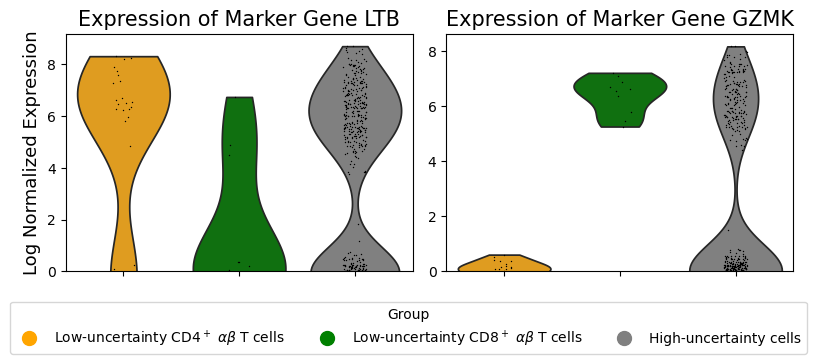

In [42]:

adata_plot_viz = adata_plot.copy()

np.random.seed(42)
for gene in [gene_x, gene_y]:
    gene_idx = adata_plot_viz.var_names.get_loc(gene)
    expr = adata_plot_viz.X[:, gene_idx].toarray().flatten()
    noise = np.random.normal(0, 0.3, size=expr.shape)
    expr_noisy = expr + noise
    adata_plot_viz.X[:, gene_idx] = expr_noisy.reshape(-1, 1)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
palette = {'CD4': 'orange', 'CD8': 'green', 'Unclear': 'gray'}

sc.pl.violin(
    adata_plot_viz, gene_x, groupby='group_short',
    stripplot=True, jitter=True, size=1, inner=None, palette=palette,
    ax=axes[0], show=False
)
axes[0].set_title('Expression of Marker Gene ' + query_adata.var['feature_name'][gene_x],fontsize=15)
axes[0].set_ylabel('Log Normalized Expression',fontsize=13)
axes[0].set_ylim(bottom=0)
axes[0].set_xticklabels([])
axes[0].set_xlabel('')

sc.pl.violin(
    adata_plot_viz, gene_y, groupby='group_short',
    stripplot=True, jitter=True, size=1, inner=None, palette=palette,
    ax=axes[1], show=False
)
axes[1].set_title('Expression of Marker Gene ' + query_adata.var['feature_name'][gene_y],fontsize=15)
axes[1].set_ylabel('')
axes[1].set_ylim(bottom=0)
axes[1].set_xticklabels([])
axes[1].set_xlabel('')

handles = [plt.Line2D([0], [0], color=palette['CD4'], lw=4,marker='o',linestyle='None', markersize=10),
           plt.Line2D([0], [0], color=palette['CD8'], lw=4,marker='o',linestyle='None', markersize=10),
           plt.Line2D([0], [0], color=palette['Unclear'], lw=4,marker='o',linestyle='None', markersize=10),]
fig.legend(handles, 
           [r'Low‑uncertainty CD4$^+\ \alpha\beta$ T cells', 
            r'Low‑uncertainty CD8$^+\ \alpha\beta$ T cells', 
            'High‑uncertainty cells'], 
           title='Group', 
           loc='upper center',
           bbox_to_anchor=(0.5, -0.00),
           ncol=3)

if axes[0].get_legend():
    axes[0].get_legend().remove()
if axes[1].get_legend():
    axes[1].get_legend().remove()

plt.tight_layout()
plt.savefig('figure/expression.pdf', bbox_inches='tight')
plt.show()

Test the effect of the beta value.

In [37]:
x = [0,0.1,0.2,0.25,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1]
ps_size = []
leaves_num = []
for name in ["celltypist_0.01_0","celltypist_0.01_0.1","celltypist_0.01_0.2","celltypist_0.01","celltypist_0.01_0.3","celltypist_0.01_0.4","celltypist_0.01_0.5","celltypist_0.01_0.6","celltypist_0.01_0.7","celltypist_0.01_0.8","celltypist_0.01_0.9","celltypist_0.01_1"]:
    result = results[name]
    ps_size.append(result['ps_len_mean'])
    leaves_num.append(result['n_covered'].mean())

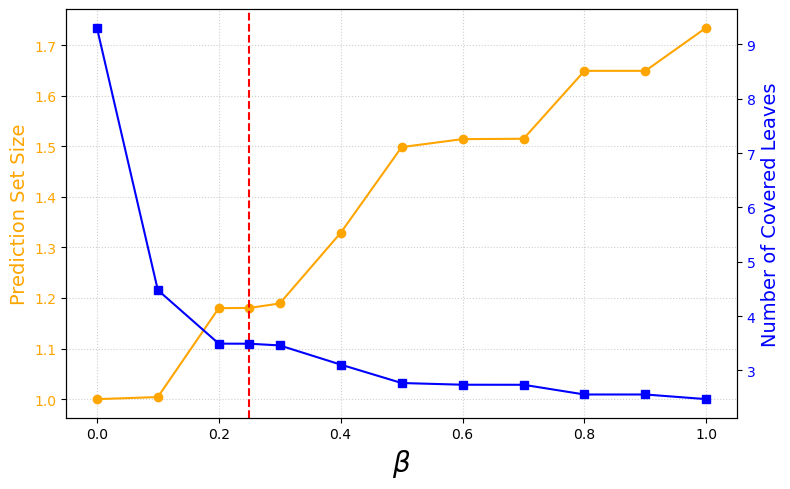

In [38]:

fig, ax1 = plt.subplots(figsize=(8, 5))


color_left = 'orange'
ax1.plot(x, ps_size, marker='o', linestyle='-', color=color_left, label='Prediction Set Size')
ax1.set_xlabel(r'$\beta$', fontsize=20)
ax1.set_ylabel('Prediction Set Size', color=color_left, fontsize=14)
ax1.tick_params(axis='y', labelcolor=color_left)


ax2 = ax1.twinx()


color_right = 'blue'
ax2.plot(x, leaves_num, marker='s', linestyle='-', color=color_right, label='Number of Covered Leaves')
ax2.set_ylabel('Number of Covered Leaves', color=color_right, fontsize=14)
ax2.tick_params(axis='y', labelcolor=color_right)

ax1.axvline(x=0.25, color='red', linestyle='--', linewidth=1.5, label='x=0.25')


lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()


plt.title('')
ax1.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("figure/betas.pdf")
plt.show()

Test the impact of different bottom level classifiers.

In [15]:
bar_dict2 = {}
keys = ['popv_celltypist_prediction', 'popv_scanvi_prediction', 'popv_xgboost_prediction', 'popv_knn_bbknn_prediction', 'popv_knn_on_scvi_prediction', 'popv_rf_prediction', 'popv_svm_prediction']
names = ["celltypist_0.01","scanvi_0.01","xgboost_0.01","bbknn_0.01","scvi_0.01","rf_0.01","svm_0.01"]

for key,name in zip(keys,names):
    classifier_file = f"output/Lung_Cell_Atlas/probability_matrix/{key}.csv"
    classifier_df = pd.read_csv(classifier_file)
    classifier_df = classifier_df[classifier_df['split']=='test']
    prob_matrix = classifier_df.iloc[:,3:]
    label = classifier_df['label']
    pred = np.argmax(prob_matrix,axis=1)
    bar_dict2[f'{name[:-5]}_original'] = (sum(pred == label)/len(label), 0, 1-sum(pred == label)/len(label))
    
    result = results[name]
    df = result['df']
    same_num = 0
    diff_num = 0
    cover_num = 0
    for cell in range(len(df)):
        if df['covered'][cell]:
            if hcc.no_cover.covers_all_nodes(frozenset({df['label_ss'][cell]}), df['prediction_set_ss'][cell]):
                same_num += 1
            else:
                cover_num += 1
        else:
            diff_num += 1
    bar_dict2[name[:-5]] = (same_num/len(df), cover_num/len(df), diff_num/len(df))
    if '_leaf' in name:
        same_num = 0
        diff_num = 0
        cover_num = 0
        for cell in range(len(df)):
            if df['lca_covered'][cell]:
                if hcc.no_cover.covers_all_nodes(frozenset({df['label_ss'][cell]}), frozenset({df['lca'][cell]})):
                    same_num += 1
                else:
                    cover_num += 1
            else:
                diff_num += 1
        bar_dict2[f'{name}_lca'] = (same_num/len(df), cover_num/len(df), diff_num/len(df))

Leave-One-Celltype-Out experiment.

In [27]:
loo_datasets = [
    ("celltypist_wo_CD4_0.05", "output/LCA_wo_CD4/hcc_result/popv_celltypist_prediction_0.05_0.25_output.csv", 0.05, "output/LCA_wo_CD4/probability_matrix/processed.h5ad", "naive thymus_derived CD4_positive_ alpha_beta T cell"),
    ("celltypist_wo_CD4_0.01", "output/LCA_wo_CD4/hcc_result/popv_celltypist_prediction_0.01_0.25_output.csv", 0.01, "output/LCA_wo_CD4/probability_matrix/processed.h5ad", "naive thymus_derived CD4_positive_ alpha_beta T cell"),
    ("celltypist_wo_CD4_0.005", "output/LCA_wo_CD4/hcc_result/popv_celltypist_prediction_0.005_0.25_output.csv", 0.005, "output/LCA_wo_CD4/probability_matrix/processed.h5ad", "naive thymus_derived CD4_positive_ alpha_beta T cell"),
    # ("celltypist_wo_capillary_0.05", "output/LCA_wo_capillary/hcc_result/popv_celltypist_prediction_0.05_0.25_output.csv", 0.25, "output/LCA_wo_capillary/probability_matrix/processed.h5ad", "capillary endothelial cell"),
    # ("celltypist_wo_capillary_0.01", "output/LCA_wo_capillary/hcc_result/popv_celltypist_prediction_0.01_0.25_output.csv", 0.25, "output/LCA_wo_capillary/probability_matrix/processed.h5ad", "capillary endothelial cell"),
    # ("celltypist_wo_capillary_0.005", "output/LCA_wo_capillary/hcc_result/popv_celltypist_prediction_0.005_0.25_output.csv", 0.25, "output/LCA_wo_capillary/probability_matrix/processed.h5ad", "capillary endothelial cell"),
    # ("celltypist_wo_club_0.05", "output/LCA_wo_club/hcc_result/popv_celltypist_prediction_0.05_0.25_output.csv", 0.25, "output/LCA_wo_club/probability_matrix/processed.h5ad", "club cell"),
    # ("celltypist_wo_club_0.01", "output/LCA_wo_club/hcc_result/popv_celltypist_prediction_0.01_0.25_output.csv", 0.25, "output/LCA_wo_club/probability_matrix/processed.h5ad", "club cell"),
    # ("celltypist_wo_club_0.005", "output/LCA_wo_club/hcc_result/popv_celltypist_prediction_0.005_0.25_output.csv", 0.25, "output/LCA_wo_club/probability_matrix/processed.h5ad", "club cell"),
]

celltypist_wo_CD4_0.05
归并后计数：
 celltype_group
effector memory CD4_positive_ alpha_beta T cell    58
others                                             17
T cell                                             16
Name: count, dtype: int64
celltypist_wo_CD4_0.01
归并后计数：
 celltype_group
hematopoietic cell                                 43
lymphoid lineage                                   30
T cell                                             13
others                                              4
effector memory CD4_positive_ alpha_beta T cell     1
Name: count, dtype: int64
celltypist_wo_CD4_0.005
归并后计数：
 celltype_group
hematopoietic cell    45
lymphoid lineage      45
others                 1
Name: count, dtype: int64


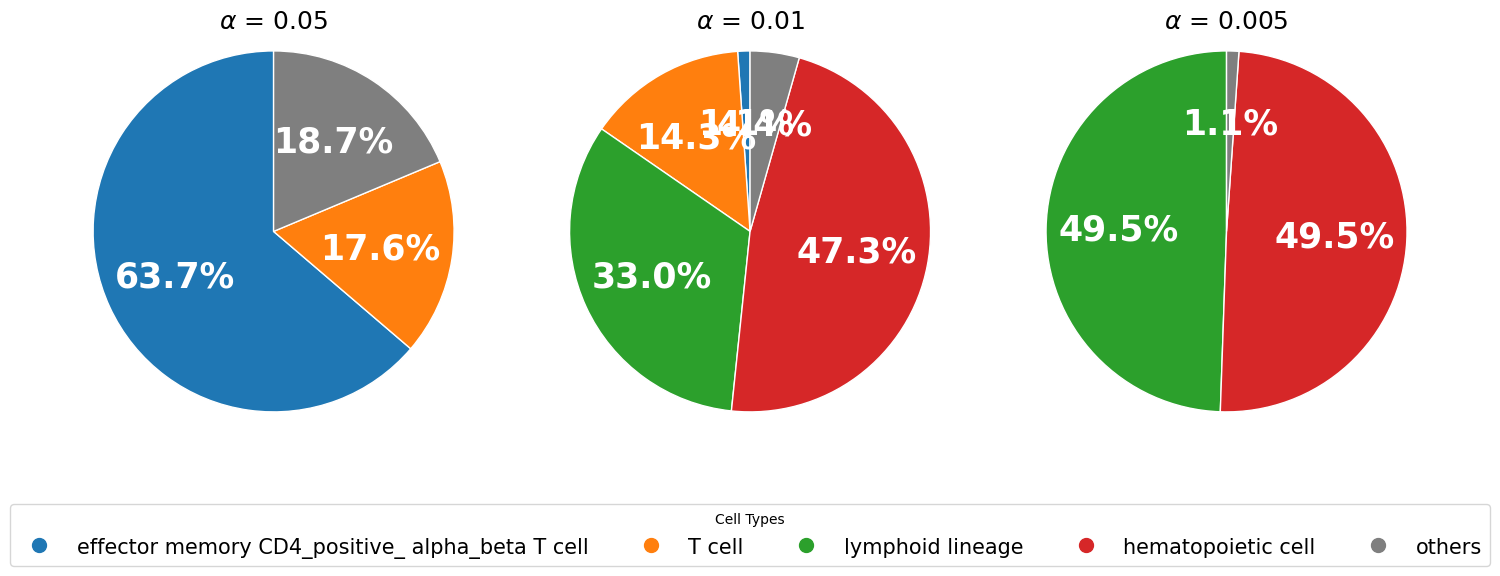

In [37]:
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

keep_labels = [
    'effector memory CD4_positive_ alpha_beta T cell',
    'T cell',
    'lymphoid lineage',
    'hematopoietic cell'
]

color_dict = {
    'effector memory CD4_positive_ alpha_beta T cell': '#1f77b4',
    'T cell': '#ff7f0e',
    'lymphoid lineage': '#2ca02c',
    'hematopoietic cell': '#d62728',
    'others': '#7f7f7f'
}

FONT_SIZE = 25

n_datasets = len(loo_datasets)  
fig, axes = plt.subplots(1, n_datasets, figsize=(5 * n_datasets, 6))
if n_datasets == 1:
    axes = [axes]

all_labels = set()


for idx, (name, dataset, alpha, processed, removed_celltype) in enumerate(loo_datasets):
    ax = axes[idx]
    print(name)
    
    df = pd.read_csv(dataset)
    adata = sc.read_h5ad(processed)
    query_adata = adata[adata.obs['split'] == 'test']
    mask = query_adata.obs['cell_type'] == removed_celltype
    df_selected = df[mask.values].copy()
    
    def extract_celltypes(pred_str, name=name):
        ret = []
        res_list = pred_str[1:-1].split(', ')
        for res in res_list:
            if '_capillary' in name:
                ret.append(res[28:-13])
            elif '_club' in name:
                ret.append(res[23:-13])
            else:
                ret.append(res[22:-13])
        return ret
    
    df_selected['predicted_celltypes'] = df_selected['prediction_set'].apply(extract_celltypes)
    df_selected['celltype_str'] = df_selected['predicted_celltypes'].apply(
        lambda lst: lst[0] if isinstance(lst, list) and len(lst) == 1 else ''
    )
    df_selected['celltype_group'] = df_selected['celltype_str'].apply(
        lambda x: x if x in keep_labels else 'others'
    )
    counts = df_selected['celltype_group'].value_counts()
    print("归并后计数：\n", counts)

    order = [label for label in keep_labels if label in counts] + \
            (['others'] if 'others' in counts else [])
    plot_counts = counts[order]
    plot_colors = [color_dict[label] for label in order]

    all_labels.update(plot_counts.index)

    wedges, texts, autotexts = ax.pie(
        plot_counts,
        labels=None,
        autopct='%1.1f%%',
        colors=plot_colors,
        startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1},
        textprops={'fontsize': FONT_SIZE},
        radius=1
    )
    for autotext in autotexts:
        autotext.set_color('white')
        autotext.set_fontweight('bold')

    ax.set_title(r'$\alpha$ = ' + str(alpha), fontsize=18)
    ax.axis('equal')


ordered_labels = [label for label in keep_labels if label in all_labels]
if 'others' in all_labels:
    ordered_labels.append('others')

handles = [
    plt.Line2D([0], [0], marker='o', color=color_dict[label],
               linestyle='None', markersize=10, label=label)
    for label in ordered_labels
]


legend = fig.legend(handles, ordered_labels, title="Cell Types",
                    loc='lower center', bbox_to_anchor=(0.5, -0.0), 
                    ncol=len(ordered_labels), fontsize=15)

fig.subplots_adjust(left=0.05, right=0.95, bottom=0.25, top=0.9)


plt.savefig('figure/combined_pie.pdf', bbox_inches='tight', bbox_extra_artists=[legend])
plt.show()

Plot the tree structure.

In [ ]:
import re
import json
import textwrap
import matplotlib.pyplot as plt
from collections import defaultdict


def read_tree_file(filepath="tree.txt"):
    with open(filepath, "r", encoding="utf-8") as f:
        return f.read()

def parse_tree(text):
    lines = [line.rstrip() for line in text.strip().splitlines() if line.strip()]
    parent_of = {}
    children_of = defaultdict(list)
    stack = []
    root = None
    for line in lines:
        cleaned = re.sub(r'[│├└─]', ' ', line)
        leading_spaces = len(cleaned) - len(cleaned.lstrip(' '))
        depth = leading_spaces // 4
        name = re.sub(r'^[│├└─\s]+', '', line).strip()
        if not name:
            continue
        while stack and stack[-1][0] >= depth:
            stack.pop()
        if stack:
            parent = stack[-1][1]
            parent_of[name] = parent
            children_of[parent].append(name)
        else:
            root = name
        stack.append((depth, name))
    if root is None:
        all_nodes = set(children_of.keys()) | set(parent_of.keys())
        roots = all_nodes - set(parent_of.keys())
        root = next(iter(roots)) if roots else None
    return root, children_of

def extract_subtree(root, children, target):
    sub_children = {}
    def dfs(node):
        if node not in children:
            return
        sub_children[node] = children[node][:]
        for child in sub_children[node]:
            dfs(child)
    dfs(target)
    return target, sub_children


MANUAL_COORDS = {
    "hematopoietic cell": (0, 0),
    "lymphoid lineage": (-5, 1.2),
    "myeloid lineage": (5, 1.2),
    "T cell": (-5, 2.4),
    "B cell": (-9, 2.4),
    "plasma cell": (-1, 2.4),
    "natural killer cell": (-7, 2.4),
    "mature NK T cell": (-3, 2.4),
    "CD4_positive_ alpha_beta T cell": (-8, 3.6),
    "CD8_positive_ alpha_beta T cell": (-2, 3.6),
    "naive thymus_derived CD4_positive_ alpha_beta T cell": (-9.5, 4.8),
    "effector memory CD4_positive_ alpha_beta T cell": (-6.5, 4.8),
    "naive thymus_derived CD8_positive_ alpha_beta T cell": (-3.5, 4.8),
    "effector memory CD8_positive_ alpha_beta T cell": (-0.5, 4.8),
    "dendritic cell": (1, 2.4),
    "macrophage": (9, 2.4),
    "megakaryocyte": (7, 2.4),
    "myeloid leukocyte": (3, 2.4),
    "monocyte": (5, 2.4),
    "classical monocyte": (2, 3.6),
    "intermediate monocyte": (5, 3.6),
    "non_classical monocyte": (8, 3.6),
}


def wrap_label(text, width=22):
    text = text.replace('_', ' ')
    return '\n'.join(textwrap.wrap(text, width=width, break_long_words=False))

def draw_tree_manual(root, children, coords, output_base="manual_tree", figsize=(14, 12), fontsize=10, highlight_nodes=None):
    if highlight_nodes is None:
        highlight_nodes = set()
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_aspect('equal')
    ax.axis('off')

    for parent, child_list in children.items():
        if parent not in coords:
            print(f"Warning: parent node '{parent}' lacks coordinates, skipping its edges.")
            continue
        xp, yp = coords[parent]
        for child in child_list:
            if child not in coords:
                print(f"Warning: child node '{child}' lacks coordinates, skipping its edges.")
                continue
            xc, yc = coords[child]
            if parent in highlight_nodes and child in highlight_nodes:
                lw = 2.5
            else:
                lw = 0.8
            ax.plot([xp, xc], [yp, yc], 'k-', lw=lw, zorder=1)

    for node, (x, y) in coords.items():
        if node not in children and node != root:
            pass
        label = wrap_label(node, width=22)
        if node in highlight_nodes:
            bbox_props = dict(boxstyle="round,pad=0.3", fc="lightcoral", ec="darkred", lw=0.8)
        else:
            bbox_props = dict(boxstyle="round,pad=0.3", fc="lightblue", ec="navy", lw=0.6)
        ax.text(x, y, label, ha='center', va='center', fontsize=fontsize,
                bbox=bbox_props, zorder=2)


    all_x = [p[0] for p in coords.values()]
    all_y = [p[1] for p in coords.values()]
    margin_x = 1.0
    margin_y = 0.5
    ax.set_xlim(min(all_x) - margin_x, max(all_x) + margin_x)
    ax.set_ylim(max(all_y) + margin_y, min(all_y) - margin_y) 
    plt.tight_layout()
    png_file = f"{output_base}"
    plt.savefig(png_file, dpi=300, bbox_inches='tight')
    print(f"Image saved:\n - {png_file}")
    plt.show()


if __name__ == "__main__":
    TREE_FILE = "data/LCA_TS/tree.txt"
    tree_text = read_tree_file(TREE_FILE)
    full_root, full_children = parse_tree(tree_text)
    target = "hematopoietic cell"
    sub_root, sub_children = extract_subtree(full_root, full_children, target)

    all_nodes = set(sub_children.keys()) | set().union(*sub_children.values()) | {sub_root}
    missing_nodes = all_nodes - set(MANUAL_COORDS.keys())
    if missing_nodes:
        print(f"Error: the following nodes are missing manual coordinates; please provide them: {missing_nodes}")
        exit(1)

    highlight_list = [
        "hematopoietic cell",
        "lymphoid lineage",
        "T cell",
        "CD4_positive_ alpha_beta T cell",
        "naive thymus_derived CD4_positive_ alpha_beta T cell"
    ]
    highlight_set = {node for node in highlight_list if node in all_nodes}

    draw_tree_manual(sub_root, sub_children, MANUAL_COORDS,
                     output_base="figure/ontology_subtree.pdf",
                     figsize=(20, 15), fontsize=16, highlight_nodes=highlight_set)